__(Support Vector Classifier) Example__

In [64]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from sklearn.model_selection import train_test_split      
from sklearn.preprocessing import StandardScaler , LabelEncoder
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

In [65]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/iris/iris.data"

# Assign colum names to the dataset
names = ['sepal-length', 'sepal-width', 'petal-length', 'petal-width', 'Target']

# Read dataset to pandas dataframe
dataset = pd.read_csv(url,names=names)

In [66]:
dataset.head()

,sepal-length,sepal-width,petal-length,petal-width,Target
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


<Axes: xlabel='petal-length', ylabel='petal-width'>

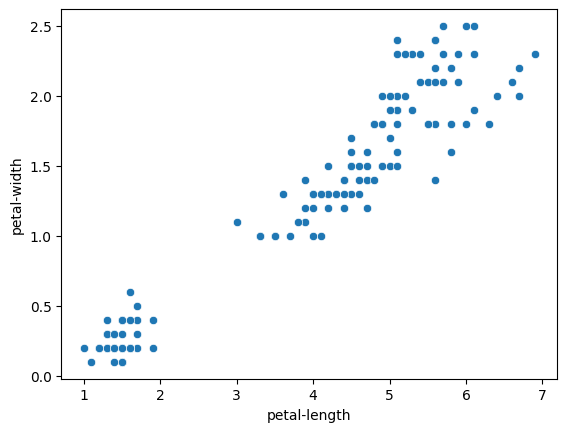

In [67]:
sns.scatterplot(x=dataset['petal-length'] , y = dataset['petal-width'])     


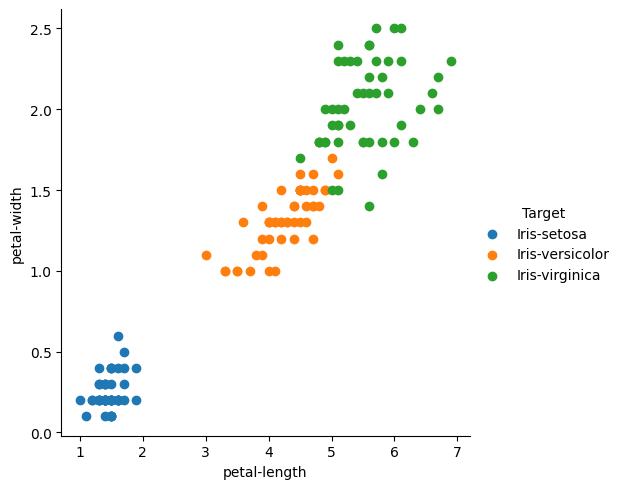

In [68]:
sns.FacetGrid(dataset , hue="Target",height=5).map(plt.scatter , 'petal-length','petal-width').add_legend()

In [69]:
dataset['Target'].value_counts()

Target
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64

In [70]:
le = LabelEncoder()   
y_enc = le.fit_transform(dataset['Target'])

In [71]:
if("Target" in dataset.columns):
    dataset.drop(columns=['Target'],inplace=True)   
x = dataset.copy()

In [79]:

x_train , x_test , y_train, y_test = train_test_split(x,y_enc,test_size=0.2,random_state=42)  
print("x_train size:",x_train.shape)    
print("x_test size:",x_test.shape)   

x_train size: (120, 4)
x_test size: (30, 4)


In [78]:
# scaling    
scale = StandardScaler()    
x_train_scaled = scale.fit_transform(x_train)   
x_test_scaled = scale.transform(x_test)

In [85]:
# hyper parameter in svm is c values for penalization gamma value
model = SVC(kernel='linear' , C=1.0)       
model.fit(x_train_scaled , y_train)   
y_test_pred =  model.predict(x_test_scaled)  

In [86]:
# finding the over fitting and underfitting       
y_train_pred = model.predict(x_train_scaled)
train_accuracy_score = accuracy_score(y_train , y_train_pred )   
test_accuracy_score = accuracy_score(y_test , y_test_pred)   
print("Train accuracy:",train_accuracy_score)  
print("Test accuracy:",test_accuracy_score)   

Train accuracy: 0.9833333333333333
Test accuracy: 0.9666666666666667


In [89]:
cm = confusion_matrix(y_test , y_test_pred)  
cm

array([[10,  0,  0],
       [ 0,  8,  1],
       [ 0,  0, 11]])

In [90]:
print(classification_report(y_test, y_test_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       1.00      0.89      0.94         9
           2       0.92      1.00      0.96        11

    accuracy                           0.97        30
   macro avg       0.97      0.96      0.97        30
weighted avg       0.97      0.97      0.97        30

